In [19]:
import torch
import importlib
import CameraParameters
importlib.reload(CameraParameters)
import os, json 

In [103]:
import os
import json
import cv2
import numpy as np
from PIL import Image, ImageOps

# opens an OpenCV window per image; click corners in grid order so click k matches points_irl[k]
# left click = add point, right click / u = undo, r = reset, enter / n = next image, esc / q = stop
def annotate_corners(image_paths, size = 224, n_rows = 5, n_cols = 5, display_scale = 3, save_path = None):
    n_points = n_rows * n_cols
    annotations = {}
    if save_path is not None and os.path.exists(save_path): # resume from earlier session
        with open(save_path) as f:
            annotations = json.load(f)

    win = "annotate corners"
    clicks = [] # (u, v) in resized image pixel coords

    def on_mouse(event, u, v, flags, param):
        if event == cv2.EVENT_LBUTTONDOWN and len(clicks) < n_points:
            clicks.append(((u + 0.5) / display_scale - 0.5, (v + 0.5) / display_scale - 0.5))
        elif event == cv2.EVENT_RBUTTONDOWN and clicks:
            clicks.pop()

    cv2.namedWindow(win)
    cv2.setMouseCallback(win, on_mouse)
    try:
        for path in image_paths:
            name = os.path.basename(path)
            if name in annotations:
                continue
            img = ImageOps.exif_transpose(Image.open(path)).convert("RGB").resize((size, size))
            base = cv2.cvtColor(np.array(img), cv2.COLOR_RGB2BGR)
            base = cv2.resize(base, (size * display_scale, size * display_scale), interpolation = cv2.INTER_NEAREST)
            clicks.clear()
            while True:
                frame = base.copy()
                pts = [(round((u + 0.5) * display_scale), round((v + 0.5) * display_scale)) for u, v in clicks]
                for k in range(1, len(pts)):
                    if k % n_cols != 0: # connect points within the same grid row
                        cv2.line(frame, pts[k - 1], pts[k], (0, 255, 0), 1)
                for k, p in enumerate(pts):
                    cv2.circle(frame, p, 4, (0, 0, 255), -1)
                    cv2.putText(frame, str(k), (p[0] + 5, p[1] - 5), cv2.FONT_HERSHEY_SIMPLEX, 0.4, (0, 255, 255), 1)
                k = len(clicks)
                status = f"{name}  {k}/{n_points}  " + (f"next: row {k // n_cols} col {k % n_cols}" if k < n_points else "enter = next")
                cv2.putText(frame, status, (5, 18), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 0), 3)
                cv2.putText(frame, status, (5, 18), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 1)
                cv2.imshow(win, frame)

                key = cv2.waitKey(20) & 0xFF
                if cv2.getWindowProperty(win, cv2.WND_PROP_VISIBLE) < 1 or key in (27, ord("q")):
                    raise KeyboardInterrupt
                if key in (13, ord("n")) and len(clicks) == n_points:
                    break
                if key == ord("u") and clicks:
                    clicks.pop()
                if key == ord("r"):
                    clicks.clear()

            annotations[name] = list(clicks)
            if save_path is not None:
                with open(save_path, "w") as f:
                    json.dump(annotations, f, indent = 1)
    except KeyboardInterrupt:
        print("stopped early, finished images are kept")
    finally:
        cv2.destroyAllWindows()
        cv2.waitKey(1)

    done = [p for p in image_paths if os.path.basename(p) in annotations]
    corners = torch.tensor([annotations[os.path.basename(p)] for p in done], dtype = torch.float32) # (B, 25, 2)
    return done, corners

In [20]:
calib_dir = r"C:\Users\simon\Coding\MonoDepthEstimation\camera_calibration"
with open(os.path.join(calib_dir, "corners.json")) as f:
    annotations = json.load(f)

image_paths = [os.path.join(calib_dir, name) for name in annotations]
corners = torch.tensor(list(annotations.values()), dtype=torch.float32)  # (B, 25, 2)

In [21]:
image_names = [
r"C:\Users\simon\Coding\MonoDepthEstimation\camera_calibration\IMG_2713.jpg",
r"C:\Users\simon\Coding\MonoDepthEstimation\camera_calibration\IMG_2714.jpg",
r"C:\Users\simon\Coding\MonoDepthEstimation\camera_calibration\IMG_2715.jpg",
r"C:\Users\simon\Coding\MonoDepthEstimation\camera_calibration\IMG_2716.jpg",
r"C:\Users\simon\Coding\MonoDepthEstimation\camera_calibration\IMG_2717.jpg",
r"C:\Users\simon\Coding\MonoDepthEstimation\camera_calibration\IMG_2718.jpg",
r"C:\Users\simon\Coding\MonoDepthEstimation\camera_calibration\IMG_2719.jpg",
r"C:\Users\simon\Coding\MonoDepthEstimation\camera_calibration\IMG_2721.jpg"
]
K, stats = CameraParameters.get_camera_params(image_names, corners)

IndexError: list index out of range

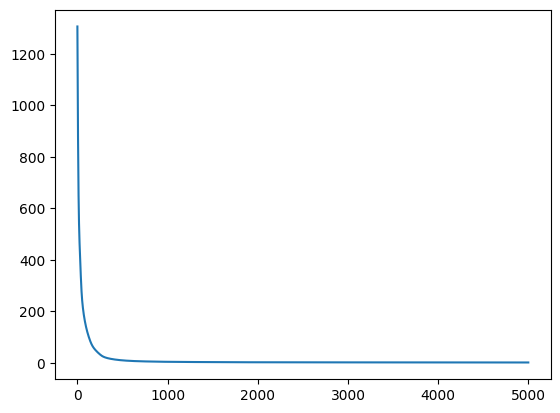

In [79]:
import matplotlib.pyplot as plt
plt.plot(stats)
stats[5000]